# The Path Less Travelled

This notebook will contain all the driving code for my honours project including synthetic data generation, real data preprocessing, model training, and evaluation. 

5030.0
[[0.00877651 0.00749611 0.00017957 ... 0.00166667 0.01481684 0.00018153]]
[[1314.7800293  1326.36999512 1336.34997559 ... 7650.5
  7764.70019531 7766.10986328]]
1000


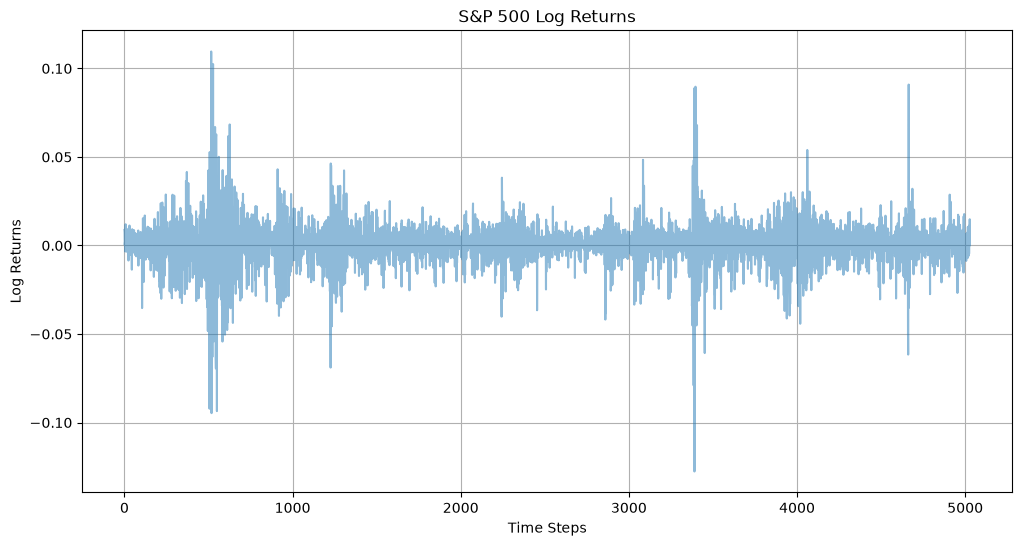

In [10]:
from wanderer import *
import numpy as np
import matplotlib.pyplot as plt

#load sp 500 
sp500 = StochasticProcess.from_json('sp500_process.json')
print(sp500.timeHorizon/sp500.timeStep)

#convert to log returns
log_returns = np.diff(np.log(sp500.paths), axis=1)
sp500_log_returns = StochasticProcess(paths=log_returns, timeHorizon=int(sp500.timeHorizon*252), timeStep =1, method = "transformed", num_paths=sp500.num_paths)

#load the oup process
oup = StochasticProcess.from_json('OUP_analytical_process.json')

print(log_returns)
print(sp500.paths)
#plot log returns
plt.figure(figsize=(12, 6))
plt.plot(sp500_log_returns.paths[0, :], alpha=0.5)
plt.title('S&P 500 Log Returns')
plt.xlabel('Time Steps')
plt.ylabel('Log Returns')
plt.grid()

print(oup.num_paths)

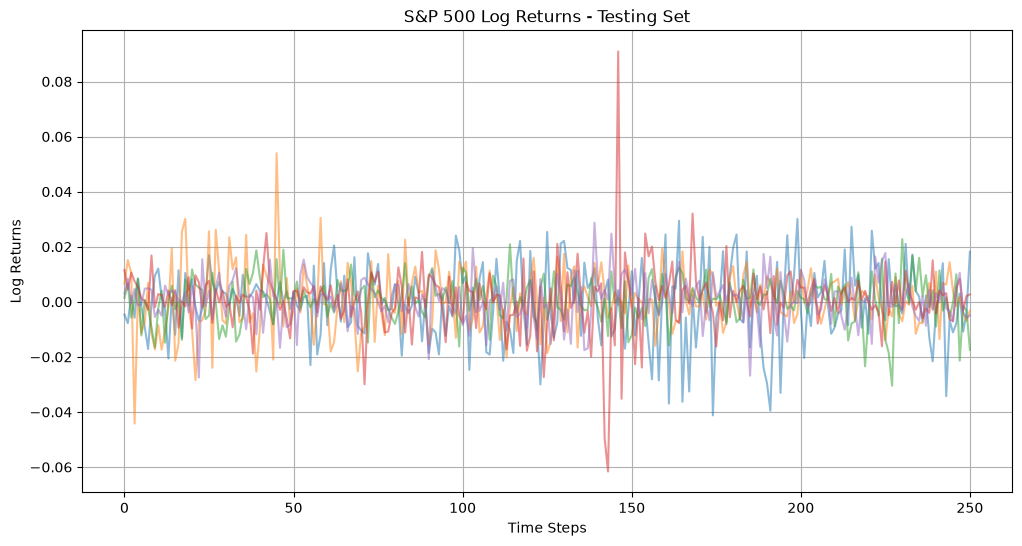

In [11]:
#time slice into one year intervals 
sliced_processes = []
for i in range(0, sp500_log_returns.timeHorizon, 251):
    #print(f"Processing time slice {i} to {i+251}")
    if i + 252 <= sp500_log_returns.timeHorizon:
        sliced_processes.append(sp500_log_returns.time_slice(i, i+251))
    
    

#stack the paths of the sliced processes into a new array
for i in range(len(sliced_processes)):
    if i == 0:
        stacked_paths = sliced_processes[i].paths
    else:
        stacked_paths = np.vstack((stacked_paths, sliced_processes[i].paths))

#split the stacked paths with 15 in training and 5 in testing
train_paths = stacked_paths[:15, :]
test_paths = stacked_paths[15:, :]

#create new StochasticProcess objects for training and testing
train_process_sp500 = StochasticProcess(paths=train_paths, timeHorizon=252, timeStep=1, method="split data", num_paths=train_paths.shape[0])
test_process_sp500 = StochasticProcess(paths=test_paths, timeHorizon=252, timeStep=1, method="split data", num_paths=test_paths.shape[0])

train_process_oup = StochasticProcess(paths=oup.paths[:750, :], timeHorizon=oup.timeHorizon, timeStep=oup.timeStep, method="split data", num_paths=750)

test_process_oup = StochasticProcess(paths=oup.paths[750:, :], timeHorizon=oup.timeHorizon, timeStep=oup.timeStep, method="split data", num_paths=250)

#plot the testing process
plt.figure(figsize=(12, 6))
for i in range(test_process_sp500.num_paths):
    plt.plot(test_process_sp500.paths[i, :], alpha=0.5)
plt.title('S&P 500 Log Returns - Testing Set')
plt.xlabel('Time Steps')
plt.ylabel('Log Returns')
plt.grid()

In [12]:
#coeffs for oup 
fourier_coeffs_oup = fourierDecomposition(num_coefficients=1000, process=train_process_oup)
kl_coeffs_oup, eigenfunctions_oup, eigen_vals_oup = KLDecomposition(num_components=2001, process=train_process_oup)


#coeffs for sp500
fourier_coeffs_sp500 = fourierDecomposition(num_coefficients=1000, process=train_process_sp500)
kl_coeffs_sp500, eigenfunctions_sp500, eigen_vals_sp500 = KLDecomposition(num_components=2001, process=train_process_sp500)

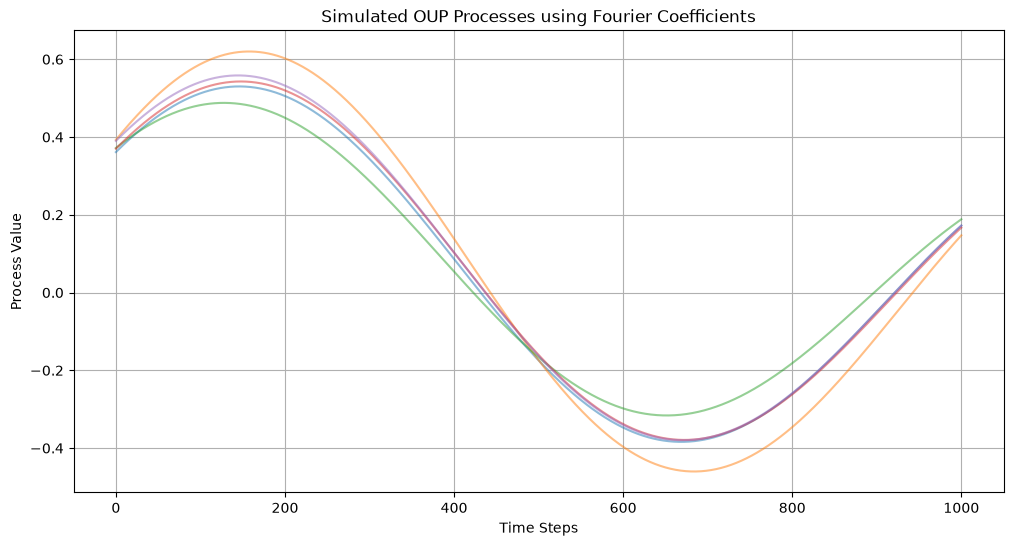

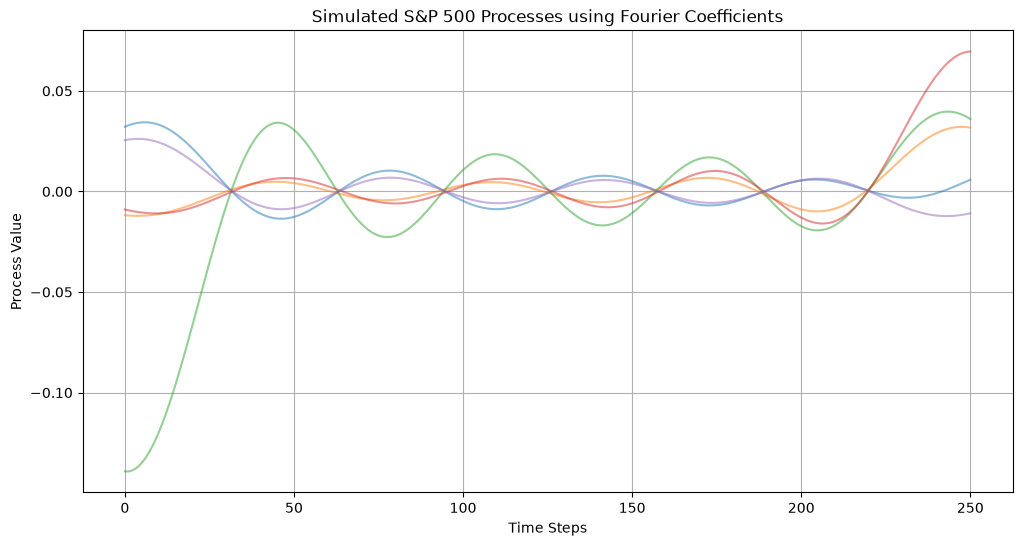

In [13]:
#find recolouring matrices for the fourier coefficients for oup and sp500
recolour_real_oup = findRecolouringMatrix(fourier_coeffs_oup.real)
recolour_imag_oup = findRecolouringMatrix(fourier_coeffs_oup.imag)

recolour_real_sp500 = findRecolouringMatrix(fourier_coeffs_sp500.real)
recolour_imag_sp500 = findRecolouringMatrix(fourier_coeffs_sp500.imag)

#simulate new samples from the fourier coefficients for oup and sp500
sim_real_oup = simulate(samples=fourier_coeffs_oup.real, recolouring_matrix=recolour_real_oup, M=1000)
sim_imag_oup = simulate(samples=fourier_coeffs_oup.imag, recolouring_matrix=recolour_imag_oup, M=1000)

sim_real_sp500 = simulate(samples=fourier_coeffs_sp500.real, recolouring_matrix=recolour_real_sp500, M=1000)
sim_img_sp500 = simulate(samples=fourier_coeffs_sp500.imag, recolouring_matrix=recolour_imag_sp500, M=1000)

#combine the real and imaginary parts to get the simulated coefficients
simulated_coeffs_oup_f = sim_real_oup + 1j * sim_imag_oup
simulated_coeffs_sp500_f = sim_real_sp500 + 1j * sim_img_sp500

#create time grids
time_grid_oup = np.linspace(0, 1, 1001)
time_grid_sp500 = np.linspace(0, 1, 251)


#reconstruct the simulated processes from the simulated coefficients
simulated_process_oup = reconstructFromFourier(simulated_coeffs_oup_f, time_grid_oup, 1001)
simulated_process_sp500 = reconstructFromFourier(simulated_coeffs_sp500_f, time_grid_sp500, 251)


#plot the the first 5 simulated processes for oup and sp500
plt.figure(figsize=(12, 6))
for i in range(5):
    plt.plot(simulated_process_oup.paths[i, :], alpha=0.5)
plt.title('Simulated OUP Processes using Fourier Coefficients')
plt.xlabel('Time Steps')
plt.ylabel('Process Value')
plt.grid()

plt.figure(figsize=(12, 6))
for i in range(5):
    plt.plot(simulated_process_sp500.paths[i, :], alpha=0.5)
plt.title('Simulated S&P 500 Processes using Fourier Coefficients')
plt.xlabel('Time Steps')
plt.ylabel('Process Value')
plt.grid()

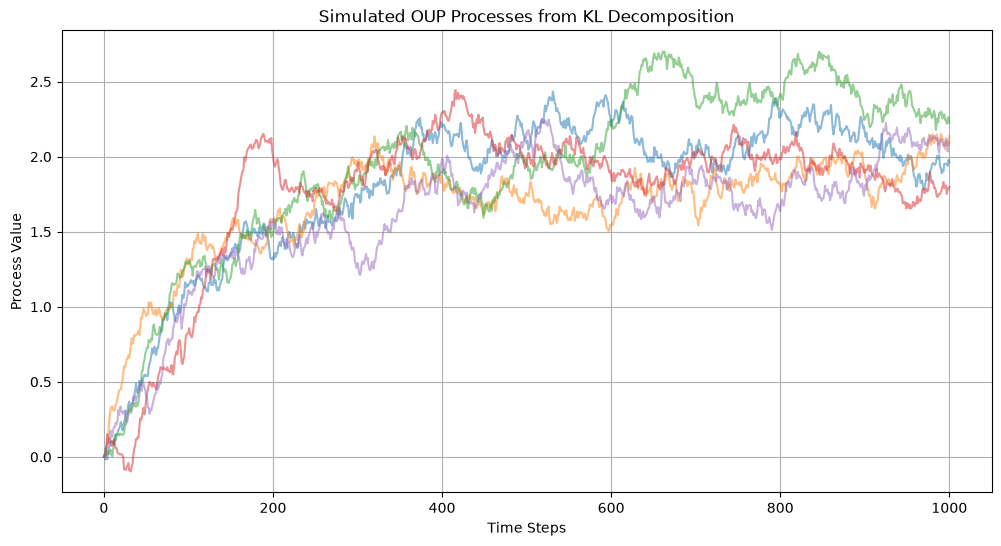

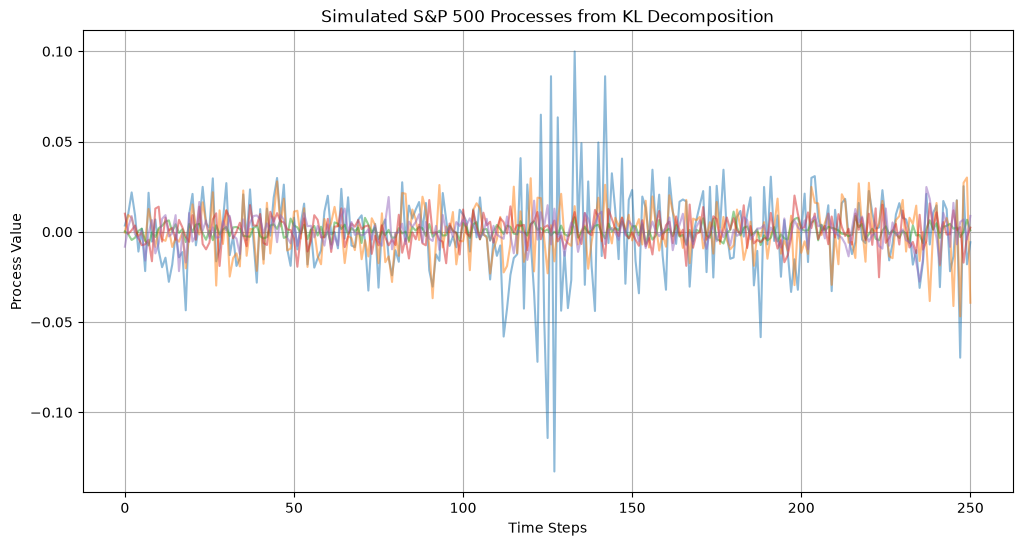

In [14]:
#find recolouring matrix for the KL coefficients
recolour_kl_oup = findRecolouringMatrix(kl_coeffs_oup)
recolour_kl_sp500 = findRecolouringMatrix(kl_coeffs_sp500)

#simulate coeffs
simulated_coeffs_kl_oup = simulate(samples=kl_coeffs_oup, recolouring_matrix=recolour_kl_oup, M=1000)
simulated_coeffs_kl_sp500 = simulate(samples=kl_coeffs_sp500, recolouring_matrix=recolour_kl_sp500, M=1000)

#simulate the process
simulated_process_kl_oup = reconstructFromKL(simulated_coeffs_kl_oup,eigenfunctions_oup, time_grid_oup, 1001)
simulated_process_kl_sp500 = reconstructFromKL(simulated_coeffs_kl_sp500,eigenfunctions_sp500, time_grid_sp500, 251)



#plot the first 5 simulated processes for KL decomposition
plt.figure(figsize=(12, 6))
for i in range(5):
    plt.plot(simulated_process_kl_oup.paths[i, :], alpha=0.5)
plt.title('Simulated OUP Processes from KL Decomposition')
plt.xlabel('Time Steps')
plt.ylabel('Process Value')
plt.grid()

plt.figure(figsize=(12, 6))
for i in range(5):
    plt.plot(simulated_process_kl_sp500.paths[i, :], alpha=0.5)
plt.title('Simulated S&P 500 Processes from KL Decomposition')
plt.xlabel('Time Steps')
plt.ylabel('Process Value')
plt.grid()

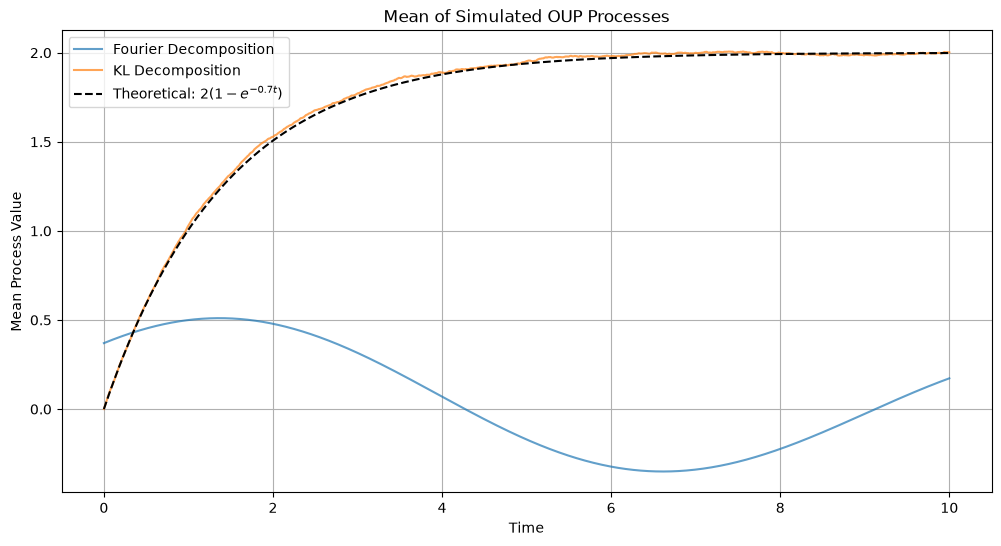

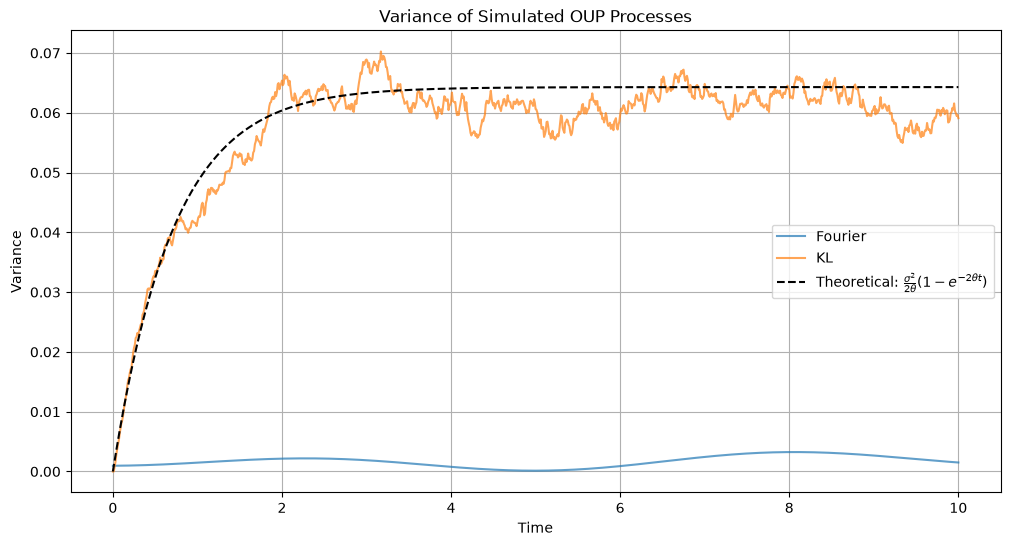

In [15]:
#compute the pointwise mean and variance of the simulated processes for both Fourier and KL decomposition

mean_simulated_process_oup_fourier = np.mean(simulated_process_oup.paths, axis=0)
var_simulated_process_oup_fourier = np.var(simulated_process_oup.paths, axis=0)
mean_simulated_process_oup_kl = np.mean(simulated_process_kl_oup.paths, axis=0)
var_simulated_process_oup_kl = np.var(simulated_process_kl_oup.paths, axis=0)

mean_simulated_process_sp500_fourier = np.mean(simulated_process_sp500.paths, axis=0)
var_simulated_process_sp500_fourier = np.var(simulated_process_sp500.paths, axis=0)
mean_simulated_process_sp500_kl = np.mean(simulated_process_kl_sp500.paths, axis=0)
var_simulated_process_sp500_kl = np.var(simulated_process_kl_sp500.paths, axis=0)

n = len(mean_simulated_process_oup_fourier)          # 1001
T = oup.timeHorizon                                   # should be 10; check this
t = np.linspace(0, T, n)                              # real time, same length as the simulated means
theoretical_mean_oup = 2 * (1 - np.exp(-0.7 * t))

plt.figure(figsize=(12, 6))
plt.plot(t, mean_simulated_process_oup_fourier, label='Fourier Decomposition', alpha=0.7)
plt.plot(t, mean_simulated_process_oup_kl, label='KL Decomposition', alpha=0.7)
plt.plot(t, theoretical_mean_oup, 'k--', label=r'Theoretical: $2(1-e^{-0.7t})$')
plt.title('Mean of Simulated OUP Processes')
plt.xlabel('Time')
plt.ylabel('Mean Process Value')
plt.legend()
plt.grid()
plt.show()


theta, sigma = 0.7, 0.3
theoretical_var_oup = sigma**2 / (2 * theta) * (1 - np.exp(-2 * theta * t))

plt.figure(figsize=(12, 6))
plt.plot(t, var_simulated_process_oup_fourier, label='Fourier', alpha=0.7)
plt.plot(t, var_simulated_process_oup_kl, label='KL', alpha=0.7)
plt.plot(t, theoretical_var_oup, 'k--', label=r'Theoretical: $\frac{\sigma^2}{2\theta}(1-e^{-2\theta t})$')
plt.title('Variance of Simulated OUP Processes')
plt.xlabel('Time')
plt.ylabel('Variance')
plt.legend()
plt.grid()
plt.show()

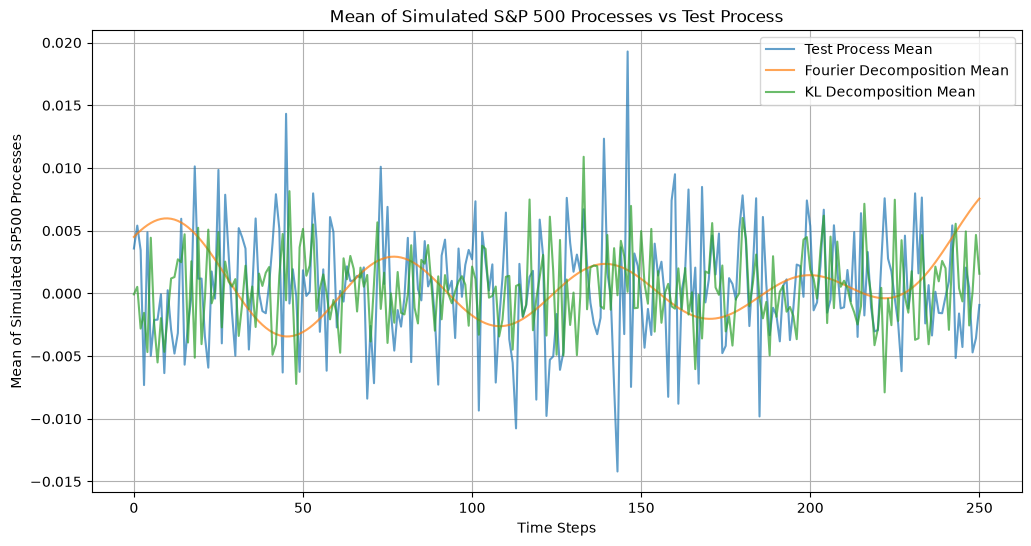

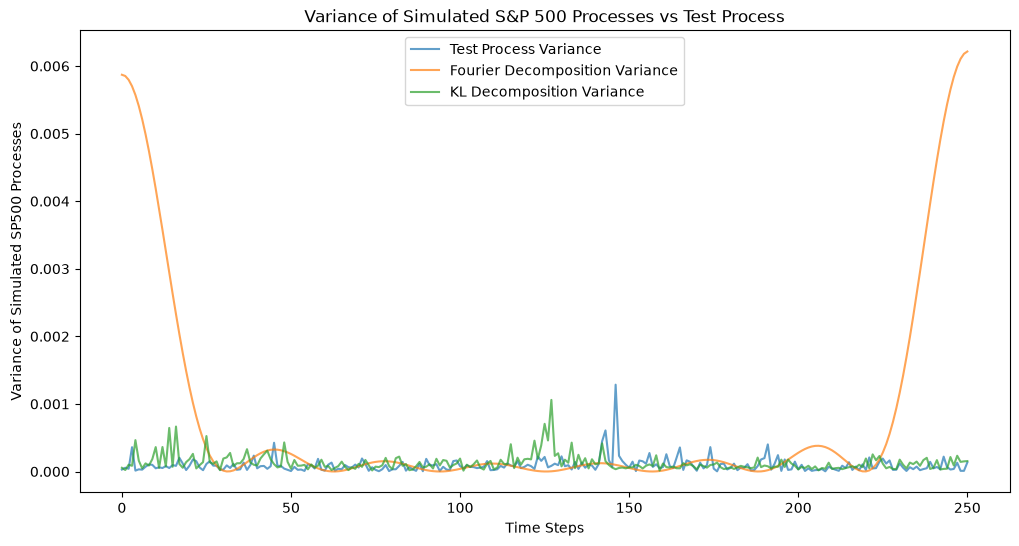

In [17]:
#plot the mean of the simulated S&P 500 processes against the mean in the test process
plt.figure(figsize=(12, 6))
plt.plot(np.mean(test_process_sp500.paths, axis=0), label='Test Process Mean', alpha=0.7)
plt.plot(mean_simulated_process_sp500_fourier, label='Fourier Decomposition Mean', alpha=0.7)
plt.plot(mean_simulated_process_sp500_kl, label='KL Decomposition Mean', alpha=0.7)
plt.title('Mean of Simulated S&P 500 Processes vs Test Process')
plt.xlabel('Time Steps')
plt.ylabel('Mean of Simulated SP500 Processes')
plt.legend()
plt.grid()  

#plot the variance of the simulated S&P 500 processes against the variance in the test process
plt.figure(figsize=(12, 6))
plt.plot(np.var(test_process_sp500.paths, axis=0), label='Test Process Variance', alpha=0.7)
plt.plot(var_simulated_process_sp500_fourier, label='Fourier Decomposition Variance', alpha=0.7)
plt.plot(var_simulated_process_sp500_kl, label='KL Decomposition Variance', alpha=0.7)
plt.title('Variance of Simulated S&P 500 Processes vs Test Process')
plt.xlabel('Time Steps')
plt.ylabel('Variance of Simulated SP500 Processes')
plt.legend()

Theory: mean 17.145, sd 1.202


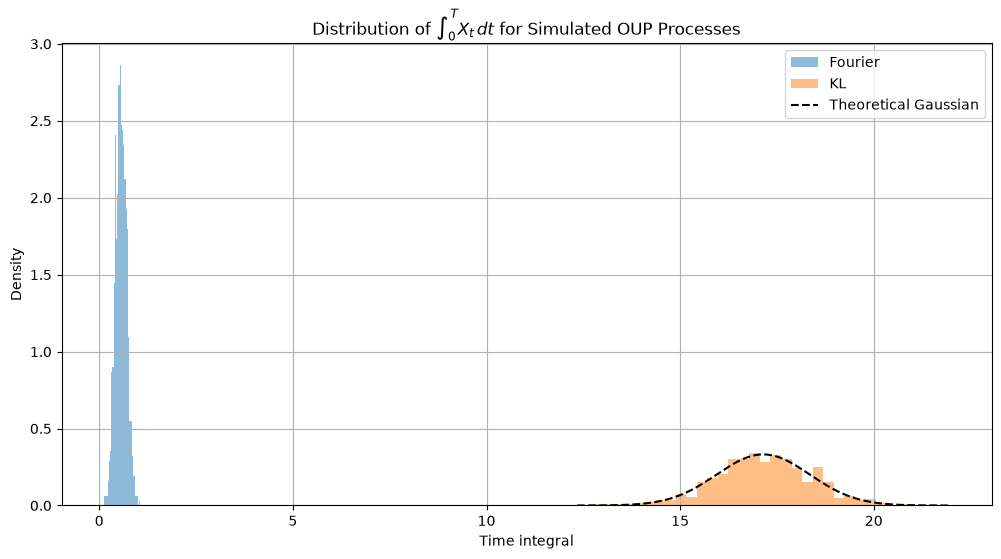

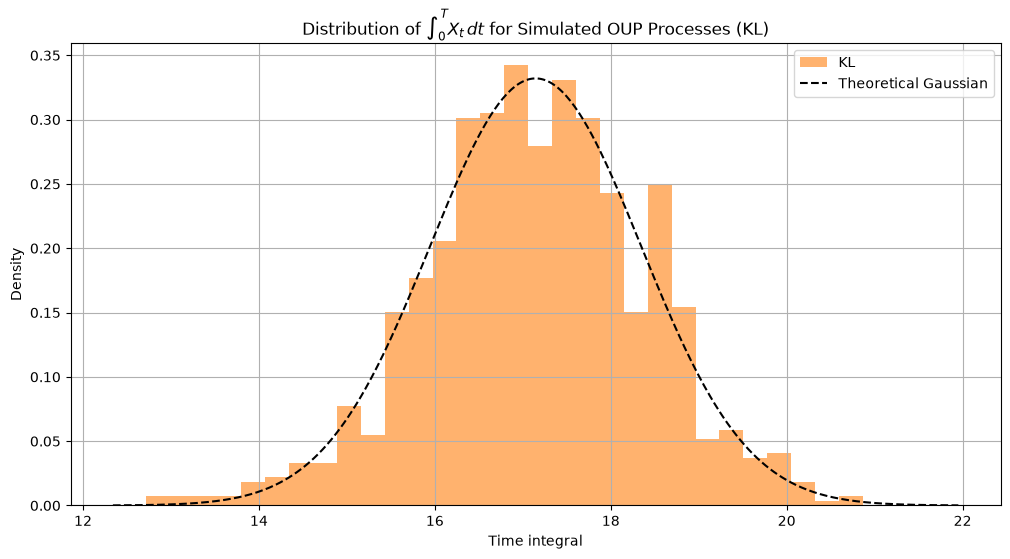

In [8]:

from scipy import stats

trap = getattr(np, "trapezoid", None) or np.trapz   # NumPy 2 / NumPy 1

theta, mu, sigma = 0.7, 2.0, 0.3     
T = oup.timeHorizon

def time_integral(paths, T):
    n = paths.shape[1]
    return trap(paths, dx=T / (n - 1), axis=1)

ti_train   = time_integral(train_process_oup.paths, T)
ti_fourier = time_integral(simulated_process_oup.paths, T)
ti_kl      = time_integral(simulated_process_kl_oup.paths, T)

# theoretical Gaussian
ti_mean = mu * (T - (1 - np.exp(-theta * T)) / theta)
ti_var  = sigma**2 / theta**2 * (T - 2 * (1 - np.exp(-theta * T)) / theta
                                 + (1 - np.exp(-2 * theta * T)) / (2 * theta))
ti_sd = np.sqrt(ti_var)
print(f"Theory: mean {ti_mean:.3f}, sd {ti_sd:.3f}")

x = np.linspace(ti_mean - 4 * ti_sd, ti_mean + 4 * ti_sd, 400)
plt.figure(figsize=(12, 6))
plt.hist(ti_fourier, bins=30, density=True, alpha=0.5, label="Fourier")
plt.hist(ti_kl, bins=30, density=True, alpha=0.5, label="KL")
plt.plot(x, stats.norm.pdf(x, ti_mean, ti_sd), "k--", label="Theoretical Gaussian")
plt.title(r"Distribution of $\int_0^T X_t\,dt$ for Simulated OUP Processes")
plt.xlabel("Time integral"); plt.ylabel("Density")
plt.legend(); plt.grid(); plt.show()

x = np.linspace(ti_mean - 4 * ti_sd, ti_mean + 4 * ti_sd, 400)

plt.figure(figsize=(12, 6))
plt.hist(ti_kl, bins=30, density=True, alpha=0.6, color="tab:orange", label="KL")
plt.plot(x, stats.norm.pdf(x, ti_mean, ti_sd), "k--", label="Theoretical Gaussian")
plt.title(r"Distribution of $\int_0^T X_t\,dt$ for Simulated OUP Processes (KL)")
plt.xlabel("Time integral"); plt.ylabel("Density")
plt.legend(); plt.grid(); plt.show()


shapes: (5, 251) (1000, 251) (1000, 251)
Test (n=5): mean +0.1038  sd 0.1365  values [-0.1327  0.1102  0.2028  0.1787  0.1601]
Fourier  mean +0.1750  sd 1.1465  KS 0.499 (p=0.115)  Wasserstein 0.8431
KL       mean +0.0862  sd 0.0926  KS 0.410 (p=0.287)  Wasserstein 0.0573


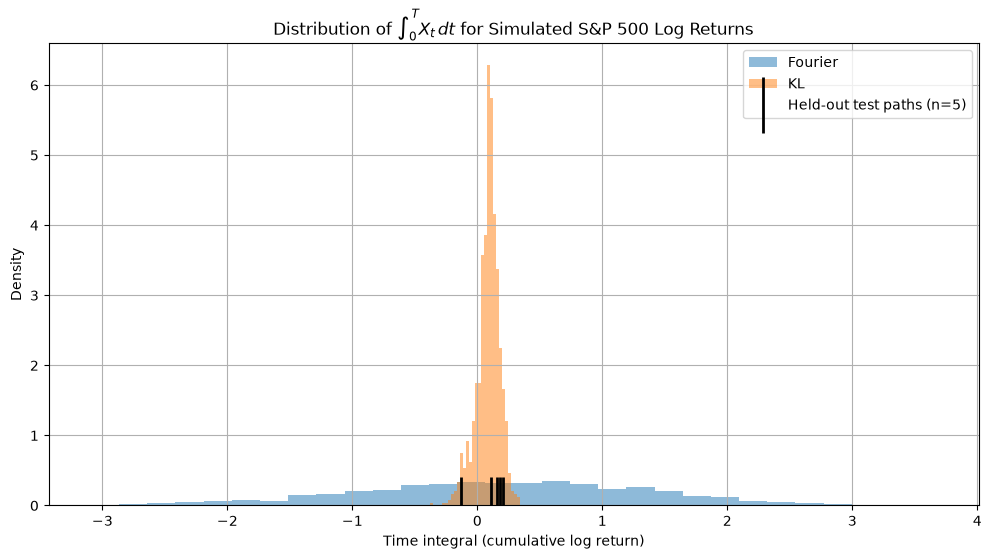

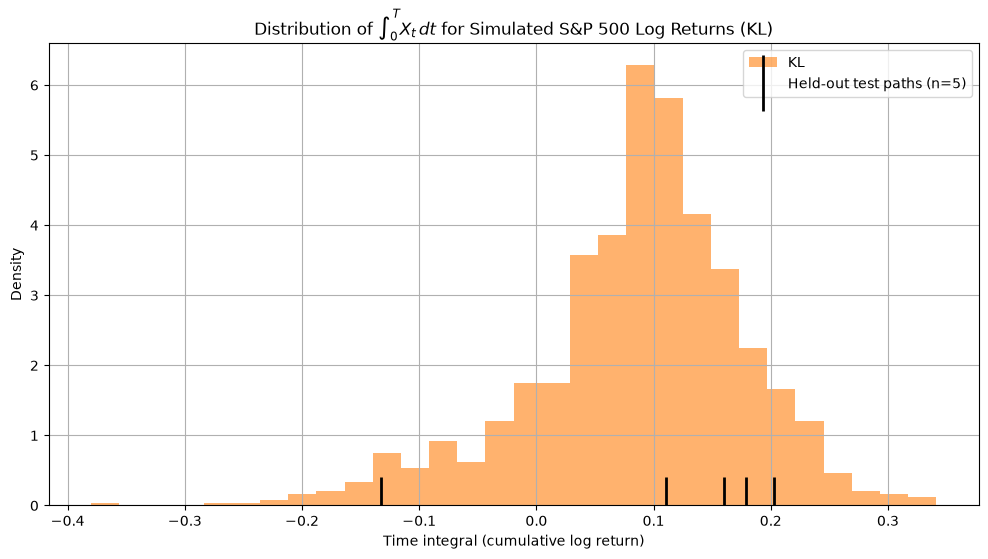

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

trap = getattr(np, "trapezoid", None) or np.trapz

def time_integral(paths, dx=1.0):
    # with daily steps (dx=1), this is approximately the horizon sum, i.e. the cumulative log return
    return trap(paths, dx=dx, axis=1)

# grid check: the integrals are only comparable if the paths have the same number of steps
print("shapes:", test_process_sp500.paths.shape, simulated_process_sp500.paths.shape,
      simulated_process_kl_sp500.paths.shape)
assert test_process_sp500.paths.shape[1] == simulated_process_sp500.paths.shape[1] == \
       simulated_process_kl_sp500.paths.shape[1], "grid length mismatch"

ti_test    = time_integral(test_process_sp500.paths)
ti_fourier = time_integral(simulated_process_sp500.paths)
ti_kl      = time_integral(simulated_process_kl_sp500.paths)

# summary and distance to the test values
print(f"Test (n={len(ti_test)}): mean {ti_test.mean():+.4f}  sd {ti_test.std(ddof=1):.4f}  values {np.round(ti_test, 4)}")
for name, x in [("Fourier", ti_fourier), ("KL", ti_kl)]:
    ks = stats.ks_2samp(x, ti_test)
    w = stats.wasserstein_distance(x, ti_test)
    print(f"{name:8s} mean {x.mean():+.4f}  sd {x.std(ddof=1):.4f}  "
          f"KS {ks.statistic:.3f} (p={ks.pvalue:.3f})  Wasserstein {w:.4f}")

# ---- combined plot ----
plt.figure(figsize=(12, 6))
plt.hist(ti_fourier, bins=30, density=True, alpha=0.5, label="Fourier")
plt.hist(ti_kl, bins=30, density=True, alpha=0.5, label="KL")
plt.plot(ti_test, np.zeros_like(ti_test), "k|", markersize=40, markeredgewidth=2,
         label=f"Held-out test paths (n={len(ti_test)})")
plt.title(r"Distribution of $\int_0^T X_t\,dt$ for Simulated S&P 500 Log Returns")
plt.xlabel("Time integral (cumulative log return)"); plt.ylabel("Density")
plt.legend(); plt.grid(); plt.show()

# ---- KL only ----
plt.figure(figsize=(12, 6))
plt.hist(ti_kl, bins=30, density=True, alpha=0.6, color="tab:orange", label="KL")
plt.plot(ti_test, np.zeros_like(ti_test), "k|", markersize=40, markeredgewidth=2,
         label=f"Held-out test paths (n={len(ti_test)})")
plt.title(r"Distribution of $\int_0^T X_t\,dt$ for Simulated S&P 500 Log Returns (KL)")
plt.xlabel("Time integral (cumulative log return)"); plt.ylabel("Density")
plt.legend(); plt.grid(); plt.show()

In [ ]:
import numpy as np
from scipy import stats
from scipy.special import ndtr

# theory for the time integral 
theta, mu, sigma = 0.7, 2.0, 0.3
T = oup.timeHorizon
ti_mean = mu * (T - (1 - np.exp(-theta * T)) / theta)
ti_var = sigma**2 / theta**2 * (T - 2 * (1 - np.exp(-theta * T)) / theta
                                + (1 - np.exp(-2 * theta * T)) / (2 * theta))
ti_sd = np.sqrt(ti_var)

def ks_norm(samples, mean, sd):
    """One-sample KS statistic and exact p-value against N(mean, sd^2)."""
    z = np.sort((samples - mean) / sd)
    n = len(z)
    cdf = ndtr(z)
    d = max(np.max(np.arange(1, n + 1) / n - cdf),
            np.max(cdf - np.arange(0, n) / n))
    return d, stats.kstwo.sf(d, n)

for name, x in [("Train", ti_train), ("Fourier", ti_fourier), ("KL", ti_kl)]:
    d, p = ks_norm(x, ti_mean, ti_sd)
    print(f"{name:8s} KS statistic {d:.4f}   p-value {p:.4f}")

Train    KS statistic 0.0302   p-value 0.4906
Fourier  KS statistic 1.0000   p-value 0.0000
KL       KS statistic 0.0261   p-value 0.4958


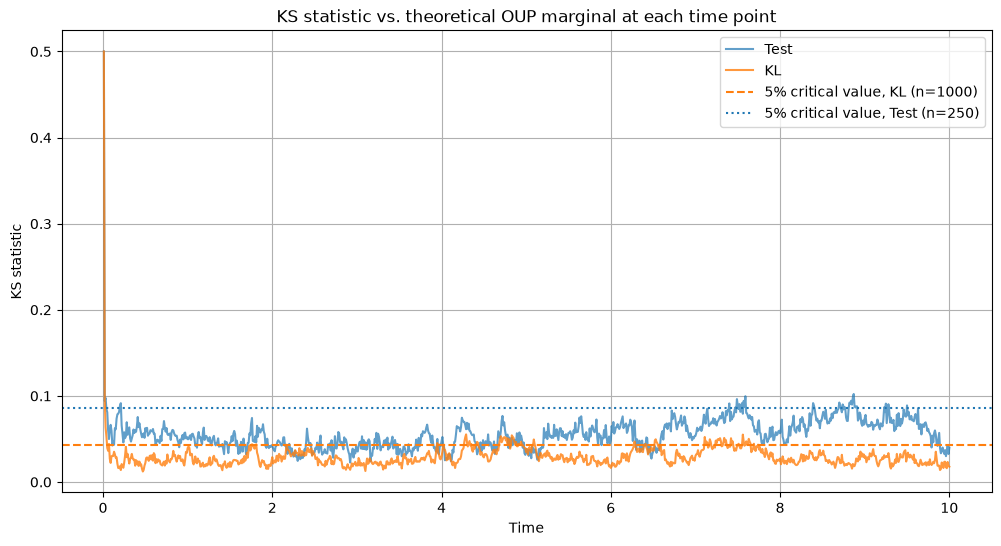

  Method   $n$  Mean $D_{t}$  Max $D_{t}$  $t$ at max  Critical value  \
0   Test   250         0.056          0.5        0.01           0.086   
1     KL  1000         0.030          0.5        0.01           0.043   

   Frac. above crit.  
0              0.034  
1              0.088  
\begin{tabular}{lrrrrrr}
\toprule
Method & $n$ & Mean $D_{t}$ & Max $D_{t}$ & $t$ at max & Critical value & Frac. above crit. \\
\midrule
Test & 250 & 0.056 & 0.500 & 0.010 & 0.086 & 0.034 \\
KL & 1000 & 0.030 & 0.500 & 0.010 & 0.043 & 0.088 \\
\bottomrule
\end{tabular}



In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import ndtr

theta, mu, sigma = 0.7, 2.0, 0.3
T = oup.timeHorizon

def ks_stat_norm_z(z):
    z = np.sort(z)
    n = len(z)
    cdf = ndtr(z)
    d_plus = np.max(np.arange(1, n + 1) / n - cdf)
    d_minus = np.max(cdf - np.arange(0, n) / n)
    return max(d_plus, d_minus)

def ks_over_time(paths, T, theta, mu, sigma):
    n_t = paths.shape[1]
    t = np.linspace(0, T, n_t)
    mean_t = mu * (1 - np.exp(-theta * t))
    sd_t = np.sqrt(sigma**2 / (2 * theta) * (1 - np.exp(-2 * theta * t)))
    ks_stat = np.full(n_t, np.nan)
    for j in range(1, n_t):                      # skip t=0
        ks_stat[j] = ks_stat_norm_z((paths[:, j] - mean_t[j]) / sd_t[j])
    return t, ks_stat

# recompute the curves under names that won't be overwritten
t, ks_test_curve = ks_over_time(test_process_oup.paths, T, theta, mu, sigma)
_, ks_kl_curve   = ks_over_time(simulated_process_kl_oup.paths, T, theta, mu, sigma)

n_kl   = simulated_process_kl_oup.paths.shape[0]
n_test = test_process_oup.paths.shape[0]
crit_kl   = 1.358 / np.sqrt(n_kl)
crit_test = 1.358 / np.sqrt(n_test)

# ---- Graph ----
plt.figure(figsize=(12, 6))
plt.plot(t, ks_test_curve, label="Test", alpha=0.7)
plt.plot(t, ks_kl_curve, label="KL", alpha=0.8, color="tab:orange")
plt.axhline(crit_kl, color="tab:orange", linestyle="--", label=f"5% critical value, KL (n={n_kl})")
plt.axhline(crit_test, color="tab:blue", linestyle=":", label=f"5% critical value, Test (n={n_test})")
plt.title("KS statistic vs. theoretical OUP marginal at each time point")
plt.xlabel("Time"); plt.ylabel("KS statistic")
plt.legend(); plt.grid(); plt.show()

# ---- Table ----
rows = []
for name, ks, n in [("Test", ks_test_curve, n_test), ("KL", ks_kl_curve, n_kl)]:
    crit = 1.358 / np.sqrt(n)
    rows.append({
        "Method": name,
        "$n$": n,
        "Mean $D_{t}$": np.nanmean(ks),
        "Max $D_{t}$": np.nanmax(ks),
        "$t$ at max": t[np.nanargmax(ks)],
        "Critical value": crit,
        "Frac. above crit.": np.nanmean(ks > crit),
    })

ks_table = pd.DataFrame(rows)
print(ks_table.round(3))
print(ks_table.to_latex(index=False, float_format="%.3f", escape=False))

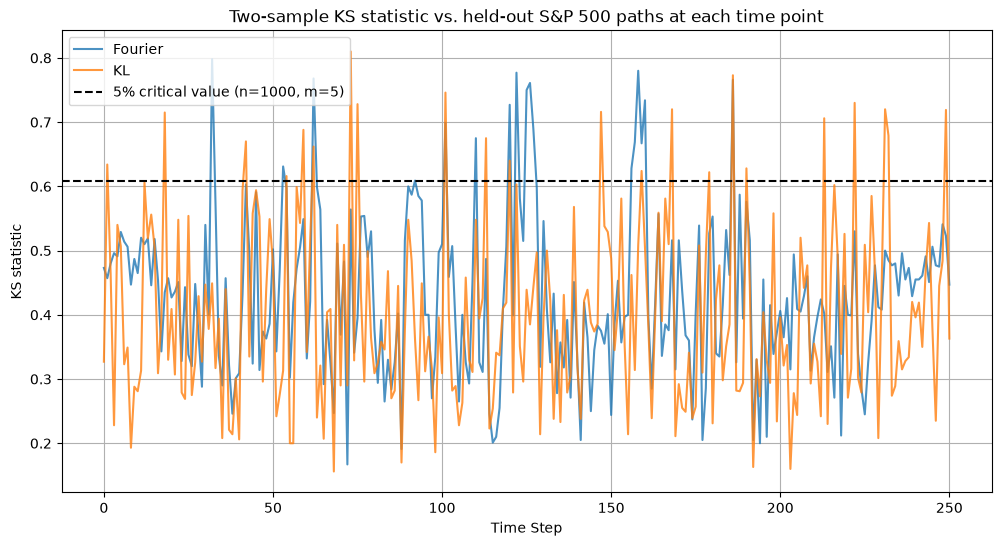

    Method   $n$  $m$  Mean $D_{t}$  Max $D_{t}$  $t$ at max  Critical value  \
0  Fourier  1000    5          0.43        0.798          32           0.609   
1       KL  1000    5          0.40        0.810          73           0.609   

   Frac. above crit.  
0              0.068  
1              0.088  
\begin{tabular}{lrrrrrrr}
\toprule
Method & $n$ & $m$ & Mean $D_{t}$ & Max $D_{t}$ & $t$ at max & Critical value & Frac. above crit. \\
\midrule
Fourier & 1000 & 5 & 0.430 & 0.798 & 32 & 0.609 & 0.068 \\
KL & 1000 & 5 & 0.400 & 0.810 & 73 & 0.609 & 0.088 \\
\bottomrule
\end{tabular}

Fourier  pooled KS 0.075  p=0.000
KL       pooled KS 0.038  p=0.056


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ref  = test_process_sp500.paths            # reference: held-out paths
sims = {"Fourier": simulated_process_sp500.paths,
        "KL":      simulated_process_kl_sp500.paths}

assert ref.shape[1] == sims["Fourier"].shape[1] == sims["KL"].shape[1], "grid length mismatch"

n_t = ref.shape[1]
m = ref.shape[0]
t = np.arange(n_t)

def ks2_over_time(sim, ref):
    return np.array([stats.ks_2samp(sim[:, j], ref[:, j]).statistic for j in range(sim.shape[1])])

def crit_2samp(n, m, c=1.358):
    return c * np.sqrt((n + m) / (n * m))

curves = {name: ks2_over_time(p, ref) for name, p in sims.items()}

# ---- Graph: two-sample KS over time ----
plt.figure(figsize=(12, 6))
for name, ks in curves.items():
    plt.plot(t, ks, label=name, alpha=0.8)
n_sim = sims["KL"].shape[0]
plt.axhline(crit_2samp(n_sim, m), color="k", linestyle="--",
            label=f"5% critical value (n={n_sim}, m={m})")
plt.title("Two-sample KS statistic vs. held-out S&P 500 paths at each time point")
plt.xlabel("Time Step"); plt.ylabel("KS statistic")
plt.legend(); plt.grid(); plt.show()

# ---- Table ----
rows = []
for name, ks in curves.items():
    crit = crit_2samp(sims[name].shape[0], m)
    rows.append({"Method": name, "$n$": sims[name].shape[0], "$m$": m,
                 "Mean $D_{t}$": ks.mean(), "Max $D_{t}$": ks.max(),
                 "$t$ at max": t[ks.argmax()], "Critical value": crit,
                 "Frac. above crit.": (ks > crit).mean()})
ks_table_sp = pd.DataFrame(rows)
print(ks_table_sp.round(3))
print(ks_table_sp.to_latex(index=False, float_format="%.3f", escape=False))

# ---- Pooled version (much more powerful) ----
for name, p in sims.items():
    r = stats.ks_2samp(p.ravel(), ref.ravel())
    print(f"{name:8s} pooled KS {r.statistic:.3f}  p={r.pvalue:.3f}")

In [11]:
#save simualted paths for sp500 
StochasticProcess.to_json(simulated_process_kl_sp500, 'simulated_process_sp500_kl.json')
StochasticProcess.to_json(simulated_process_sp500, 'simulated_process_sp500_fourier.json')
